In [1]:
%run geo_zones

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 19, Finished, Available, Finished, True)

In [2]:
%run manage_files

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 26, Finished, Available, Finished, True)

In [3]:
%run transformation

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 40, Finished, Available, Finished, True)

In [4]:
from pyspark.sql.functions import *
import matplotlib.pyplot as plt

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 41, Finished, Available, Finished, False)

In [6]:
YELLOW_TRIPDATA_FOLDER_PATH = "Files/NYC_Taxi/yellow_tripdata"
YELLOW_TRIPDATA_SCHEMA = {
    "pickup_datetime": "timestamp",
    "dropoff_datetime": "timestamp",
    "passenger_count": "integer",
    "trip_distance": "double",
    "pickup_location_id": "integer",
    "dropoff_location_id": "integer",
    "pickup_longitude": "double",
    "pickup_latitude": "double",
    "dropoff_longitude": "double",
    "dropoff_latitude": "double",
    "fare_amount": "double",
    "total_amount": "double",
    "tip_amount": "double"
}
YELLOW_TRIPDATA_COLUMN_MAPPING = {
    "Trip_Pickup_DateTime": "pickup_datetime",
    "tpep_pickup_datetime": "pickup_datetime",
    "Trip_Dropoff_DateTime": "dropoff_datetime",
    "tpep_dropoff_datetime": "dropoff_datetime",
    "Passenger_Count": "passenger_count",
    "Trip_Distance": "trip_distance",
    "PULocationID": "pickup_location_id",
    "DOLocationID": "dropoff_location_id",
    "Start_Lon": "pickup_longitude",
    "Start_Lat": "pickup_latitude",
    "End_Lon": "dropoff_longitude",
    "End_Lat": "dropoff_latitude",
    "Fare_Amt": "fare_amount",
    "Total_Amt": "total_amount",
    "Tip_Amt": "tip_amount"
}

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 43, Finished, Available, Finished, False)

In [7]:
def fill_empty_numeric(df, schema, excluded_columns=None):
    excluded_columns = excluded_columns or []
    numeric_columns = [(column, data_type) for column, data_type in schema.items() if data_type in ["integer", "double"] and column not in excluded_columns]
    for column, data_type in numeric_columns:
        if data_type == "double":
            df = df.withColumn(column, nanvl(col(column), lit(0.0)))
    return df.fillna(0, subset=[column for column, _ in numeric_columns])

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 44, Finished, Available, Finished, False)

In [8]:
file_paths = get_parquet_files(YELLOW_TRIPDATA_FOLDER_PATH)
dfs = []
for file_path in file_paths[:3]:
    df = read_parquet_file(file_path)
    df = rename_columns(df, YELLOW_TRIPDATA_COLUMN_MAPPING)
    df = add_missing_columns(df, YELLOW_TRIPDATA_SCHEMA)
    df = cast_columns(df, YELLOW_TRIPDATA_SCHEMA)
    df = fill_empty_numeric(df, YELLOW_TRIPDATA_SCHEMA, ["pickup_location_id", "dropoff_location_id"])
    df = select_columns(df, YELLOW_TRIPDATA_SCHEMA)
    dfs.append(df)

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 45, Finished, Available, Finished, False)

In [9]:
taxi_df = dfs[0]
for df in dfs[1:]:
    taxi_df = taxi_df.unionByName(df)

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 46, Finished, Available, Finished, False)

In [10]:
print(f"Number of rows: {taxi_df.count()}")
taxi_df.printSchema()
display(taxi_df.limit(5))

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 47, Finished, Available, Finished, False)

Number of rows: 41859906
root
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = false)
 |-- pickup_location_id: integer (nullable = true)
 |-- dropoff_location_id: integer (nullable = true)
 |-- pickup_longitude: double (nullable = false)
 |-- pickup_latitude: double (nullable = false)
 |-- dropoff_longitude: double (nullable = false)
 |-- dropoff_latitude: double (nullable = false)
 |-- fare_amount: double (nullable = false)
 |-- total_amount: double (nullable = false)
 |-- tip_amount: double (nullable = false)



SynapseWidget(Synapse.DataFrame, 2b35c613-b34f-47e3-b87e-2132c71e6bdc)

In [11]:
numeric_columns = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "total_amount",
    "tip_amount",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude"
]
taxi_df.select(numeric_columns).summary("count", "min", "25%", "50%", "75%", "90%", "95%", "99%", "99.9%", "max").show(truncate=False)

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 48, Finished, Available, Finished, False)

+-------+---------------+-------------+-----------+-----------------+----------+------------------+---------------+------------------+----------------+
|summary|passenger_count|trip_distance|fare_amount|total_amount     |tip_amount|pickup_longitude  |pickup_latitude|dropoff_longitude |dropoff_latitude|
+-------+---------------+-------------+-----------+-----------------+----------+------------------+---------------+------------------+----------------+
|count  |41859906       |41859906     |41859906   |41859906         |41859906  |41859906          |41859906       |41859906          |41859906        |
|min    |0              |0.0          |2.5        |2.5              |0.0       |-1775.588693      |-182.942403    |-784.2999999999998|-53.623531      |
|25%    |1              |1.0          |5.7        |5.9              |0.0       |-73.99158799999998|40.736423      |-73.99110799999998|40.735405       |
|50%    |1              |1.68         |7.7        |8.099999999999998|0.0       |-73.9815

In [12]:
taxi_df.select(count(when(col("passenger_count") > 50, 1)).alias("num_of_passengers_more_than_50")).show()

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 49, Finished, Available, Finished, False)

+------------------------------+
|num_of_passengers_more_than_50|
+------------------------------+
|                           247|
+------------------------------+



In [13]:
display(taxi_df.filter(col("passenger_count") > 50))

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 50, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, b5d8605d-85e4-4e74-bfc4-bda01fbe65aa)

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 51, Finished, Available, Finished, False)

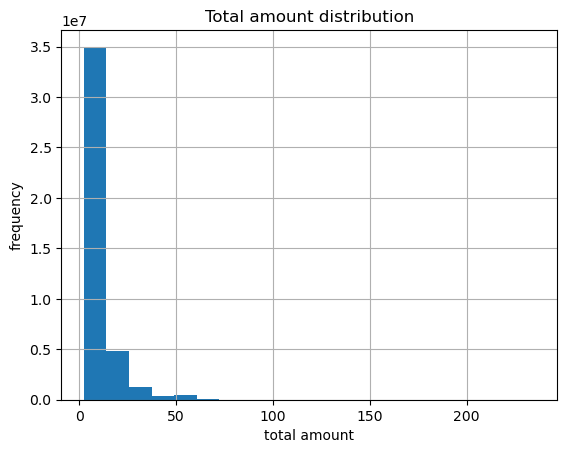

In [14]:
taxi_df.select('total_amount').toPandas().hist(bins=20)
plt.xlabel('total amount')
plt.ylabel('frequency')
plt.title('Total amount distribution')
plt.show()

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 52, Finished, Available, Finished, False)

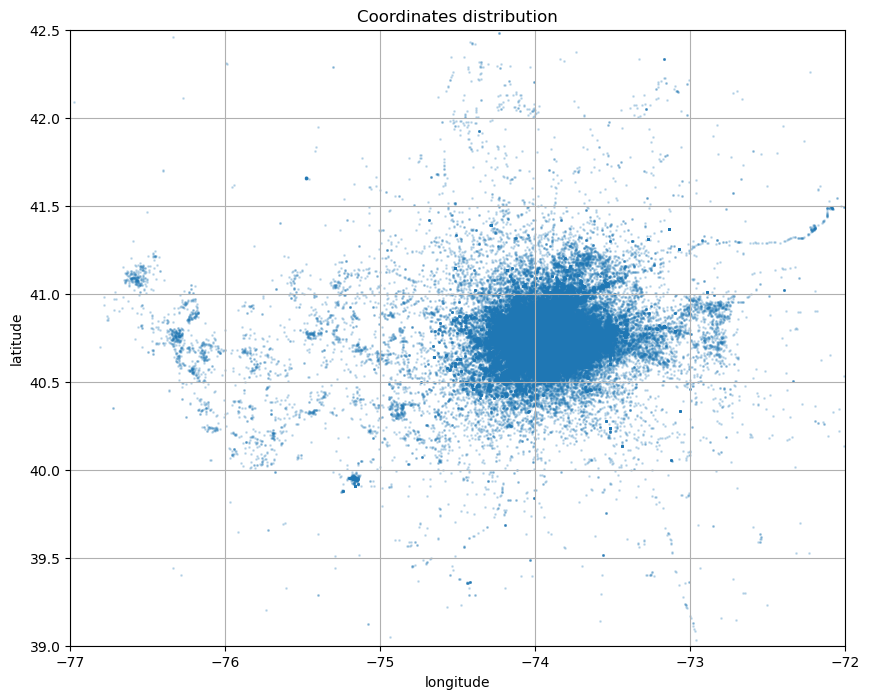

In [15]:
coordinates_df = taxi_df.select(col("pickup_longitude").alias("longitude"), col("pickup_latitude").alias("latitude"))\
    .union(taxi_df.select(col("dropoff_longitude").alias("longitude"), col("dropoff_latitude").alias("latitude")))
pdf = coordinates_df.toPandas()
plt.figure(figsize=(10, 8))
plt.scatter(pdf["longitude"], pdf["latitude"], s=1, alpha=0.2)
plt.xlim(-77, -72)
plt.ylim(39, 42.5)
plt.title("Coordinates distribution")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.grid()
plt.show()

In [16]:
display(taxi_df.filter(col("dropoff_latitude") > 250))

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 53, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, c562e4e9-aaa3-4f6a-9ef6-0b8e9999fe24)

In [17]:
sedona = prepare_spatial_processing(spark, TAXI_ZONES_SHAPEFILE_FOLDER_PATH)

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 54, Finished, Available, Finished, False)

In [18]:
sedona.sql("""
    SELECT ST_AsText(ST_Boundary(new_geometry))
    FROM zones
    WHERE LocationID = 164
""").show(truncate=False)

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 55, Finished, Available, Finished, False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [19]:
sedona.sql("""
    SELECT LocationID
    FROM zones
    WHERE ST_Intersects(new_geometry, ST_Point(-73.98362519999995, 40.74394311499994))
""").show()

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 56, Finished, Available, Finished, False)

+----------+
|LocationID|
+----------+
|       164|
|       170|
+----------+



In [22]:
sedona.sql("""
    SELECT LocationID
    FROM zones
    WHERE ST_Contains(new_geometry, ST_Point(-73.98362519999995, 40.74394311499994))
""").show()

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 60, Finished, Available, Finished, True)

+----------+
|LocationID|
+----------+
+----------+



In [21]:
sedona.sql("""
    SELECT LocationID
    FROM zones
    WHERE ST_Contains(new_geometry, ST_Point(3555.912803, 935.525308))
""").show()

StatementMeta(, da3d078f-a13d-403b-ae1f-d1a4e81cf914, 58, Finished, Available, Finished, False)

+----------+
|LocationID|
+----------+
+----------+



In [ ]:
df = spark.read.parquet("Files/NYC_Taxi/yellow_tripdata/yellow_tripdata_2026-09.parquet")
df.select(min(col("tpep_pickup_datetime"))).show()

In [ ]:
display(df.filter(col("tpep_pickup_datetime")=="2009-01-01 09:32:44"))